# Predict the beam from a recording
Start with the projection column in **neoarm_forward.ipynb**. Can its response to the console predict the centre of a *new image*, including the sign of each detector coordinate? Here the target is the independent PyJEM-compatible virtual microscope, operated by the same recording script as the real NEOARM. The fit gets only the recording. It never reads the virtual instrument's lens positions, DAC laws or simulator-fit JSON.

At fixed HT, objective, alpha and corrector, a small change of CLA1 or CLA2 gives a change of position and tilt at the specimen. Fit those combinations first. The transfer from specimen to SightX comes from TemGym. Test whether one column accounts for several MAG and DIFF rows. Where it misses, use measured local slopes within the recorded envelope. All errors below are distances on SightX in camera pixels relative to the frame centre, with positive x to the right and positive y down.

In [1]:
from pathlib import Path
import csv
import json
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

folder = Path.cwd()
if not (folder / "neoarm_forward.py").exists():
    folder = folder / "examples/microscope_inversion"
sys.path.insert(0, str(folder))
from neoarm_forward import parameters, LENSES, STEER, VOLTAGE

### Record the calibration

From this folder run `python at_the_microscope/record_predictor.py --simulated pilot --compact` in the TemGym environment. The recorder operates the offline PyJEM interface and saves a raw image, actual DAC readbacks, time, quality flags and a preassigned split for every retained exposure. To analyze a particular recording, set `NEOARM_PILOT` to its folder. The fit reads the table and its measured image features.

| Compact calibration | Frames to keep | What they measure |
|---|---|---|
| MAG 8k, 20k, 30k, 40k, 500k; DIFF 15, 40, 200 cm | A reference and CLA1/CLA2 in ±x and ±y at each row (72) | The two-axis response and beam origin across both MAG branches and DIFF |
| MAG 40k and DIFF 40 cm | Change IL1, IL2, IL3 and PL1 individually to either side of nominal. At each endpoint, take ±x with CLA1 and ±x with CLA2 (64) | A lens changes the response even of a coil that looks inactive at nominal focus |
| Spots 0–4 at the two anchors | Three nearby CL3 readbacks per spot, matched between MAG and DIFF. Keep one entire spot for testing (24 fit, 6 test) | How the spot preset and brightness affect the incident beam and its width |

The simulator design calls for **160 training images** before retries. Keep the independent compound moves, whole held-out rows, and repeated 40k checks in the recording. Dark, centring and trial exposures also consume camera time. Dropping the training frames used for one of the independent control directions can lose that direction from the fit.

**On the NEOARM**, use a current console survey, vacuum in the beam and an unclipped reference. Park DIFF at its objective-on 40 cm row before returning to MAG 40k. Start at 200 kV, alpha 0, spot index 0–4, with the gun, objective, aperture, stage and corrector held fixed. Note the corrector alignment at start and finish. The hardware entry point is `python at_the_microscope/record_predictor.py --for-real pilot --compact`. It adds DIFF 8 cm and measures IS1, IS2 and PLA along both axes at two anchors per branch. The simulated target does not exercise those six axes. Preserve full per-frame readbacks through each branch switch. PL1 at MAG 25k is at its rail and that row is outside this calibration.

Approach each lens from below. Omit a wobble side that exceeds a DAC rail. Reduce a wobble or coil kick when the spot approaches the frame edge. For each missed tolerance, inspect the controls and row first. A low-MAG lens error calls for an extra wobble in that branch. A drifting 40k reference calls for a repeat at a second MAG or DIFF row before updating the incoming beam. Retain fresh settings to test the revised fit.

Omit `--compact` in simulation for the broad rehearsal and the full-versus-compact comparison. The notebook accepts either completed recording.

In [2]:
if "NEOARM_PILOT" in os.environ:
    session = Path(os.environ["NEOARM_PILOT"]).expanduser()
else:
    sessions = sorted((folder / "at_the_microscope/output/predictor").glob("*/console.json"), reverse=True)
    session = next((p.parent for p in sessions if json.loads(p.read_text()).get("pilot_complete") is True), None)
    if session is None:
        raise FileNotFoundError("Run the simulated pilot command above, or set NEOARM_PILOT to a pilot folder.")
if json.loads((session / "console.json").read_text()).get("pilot_complete") is not True:
    raise ValueError("This pilot was interrupted; select a completed recording.")
with (session / "table.csv").open(newline="") as stream:
    all_frames = [r for r in csv.DictReader(stream) if r["stage"] == "pilot"]
if not all_frames:
    raise ValueError("The selected recording has no pilot frames.")
frames = [r for r in all_frames if r["beam_usable"].lower() == "true"
          and float(r.get("beam_saturated") or 0) == 0
          and np.isfinite([float(r["beam_x_px"]), float(r["beam_y_px"])]).all()]
if not frames:
    raise ValueError("No usable unsaturated pilot frames.")
for kind in sorted({r["split"] for r in all_frames}):
    print(kind, "usable / recorded", sum(r["split"] == kind for r in frames), "/", sum(r["split"] == kind for r in all_frames))
print("Calibration design:",json.loads((session/"console.json").read_text()).get("pilot_design","dense"))
print(session, frames[0].get("source", ""), len(frames), "usable /", len(all_frames), "recorded")
print("Detector centroids and one-axis RMS widths are from the saved frames.")

check usable / recorded 14 / 14
held_move usable / recorded 28 / 28
held_row usable / recorded 77 / 77
held_spot usable / recorded 6 / 6
prospective usable / recorded 21 / 21
train usable / recorded 599 / 602
Calibration design: dense
/Users/landers/davids_sandbox/TemGymCore/examples/microscope_inversion/at_the_microscope/output/predictor/2026-11-17_234820 simulated 745 usable / 748 recorded
Detector centroids and one-axis RMS widths are from the saved frames.


### Which controls can this recording distinguish?

For each named selector row, keep the *nominal lens readbacks* to calculate its wobble in DAC. Measure deflections relative to one fixed reference per branch, so a change of preset enters the prediction. CLA and IS are separate x/y pairs. A constant input, or a stigmator that changes only when the branch changes, has no independently measured slope in that branch. A quantitative prediction assumes the recorded HT, objective and aperture, the same lens approach direction, and a beam wholly on the camera.

In [3]:
labels = np.array([int(r["mode_row"]) for r in frames])
modes = np.array([r["function_mode"] for r in frames])
branch = np.where(modes == "DIFF", 2, np.where(labels < 30000, 0, 1))
split = np.array([r["split"] for r in frames])
train = split == "train"
role = np.array([r["role"] for r in frames])
nominal = np.array([r["setting"] in ("row", "", "reference") for r in frames])
observed = np.array([[float(r["beam_x_px"]), float(r["beam_y_px"])] for r in frames])
lens_names = LENSES[3:]
lens = np.array([[float(r[name]) for name in lens_names] for r in frames])
steer_names = [f"{name}_{axis}" for name in STEER for axis in "xy" if f"{name}_{axis}" in frames[0]]
illum_names = ["CL1", "CL3"]
actuators = np.array([[float(r[name]) for name in steer_names + illum_names] for r in frames])
groups = sorted(set(zip(branch.tolist(), labels.tolist())))
ref_lens = {}
ref_actuators = {}
for b, label in groups:
    rows = [r for r in all_frames if r["function_mode"] == ("DIFF" if b == 2 else "MAG")
            and int(r["mode_row"]) == label and r["role"] == "reference" and r["setting"] == "row"]
    if not rows:
        raise ValueError(f"Missing nominal readback for branch {b}, row {label}")
    ref_lens[b,label] = np.array([float(rows[0][k]) for k in lens_names])
for b in range(3):
    rows = train & (branch == b) & nominal & (role == "reference")
    ref_actuators[b] = np.median(actuators[rows], axis=0)
lens_change = (lens - [ref_lens[b,label] for b,label in zip(branch,labels)]) / 1000
act_change = (actuators - [ref_actuators[b] for b in branch]) / 1000
# A deflector preset alone has no independently measured effect. Use axes exercised inside a train row.
exercised = np.zeros(len(steer_names) + 2, dtype=bool)
for b, label in groups:
    rows = train & (branch == b) & (labels == label)
    if rows.any():
        exercised |= np.ptp(actuators[rows], axis=0) > 0
# SpotA and stigmator presets only move together with a selector/spot in this recipe.
# Keep those values as applicability checks. CL1 represents the joint spot preset.
all_names = steer_names + illum_names
tied = np.array([name.startswith(("SpotA_", "OLs_")) for name in all_names])
exercised[tied] = False
names = np.array(steer_names + illum_names)[exercised].tolist()
motion = np.c_[act_change[:, exercised], lens_change]
print("Measured directions:", names + list(lens_names))
print("Held constant or tied to a preset:", np.array(steer_names + illum_names)[~exercised].tolist())


Measured directions: ['CLA1_x', 'CLA1_y', 'CLA2_x', 'CLA2_y', 'CL1', 'CL3', 'IL1', 'IL2', 'IL3', 'PL1']
Held constant or tied to a preset: ['IS1_x', 'IS1_y', 'IS2_x', 'IS2_y', 'PLA_x', 'PLA_y', 'SpotA_x', 'SpotA_y', 'OLs_x', 'OLs_y']


### 1. Fit the four projection lenses to signed pairs

Subtract images recorded at the opposite ends of a deflector kick and divide by two. This cancels the beam's starting position and any constant camera offset. Fit x and y together in pixels. For each CLA axis, the unknown incoming ray at IL1 has a transverse displacement and a tilt per DAC. TemGym gives the complex detector response to each. This folds the fixed objective, corrector and condenser transfer into measured input coefficients at the chosen illumination setting.

Begin with notebook one's lens strengths, windings and drawing. Allow four positive strengths, three upstream gaps and four positive lens thicknesses to change. The final lens-to-screen gap sets a length convention. A weak prior keeps flat directions near the start. Hold out the positive lens wobbles among the training frames to choose the camera handedness and whether the new instrument needs the console-derived focusing correction. Within each candidate fit, compare independent starts using the training objective: wrong optical solutions can look locally stable. Fit the selected model again on all training pairs. The separate held rows, compound moves and spot test stay outside both fits.

In [4]:
# The column downstream of IL1 is common to all coils. Source, objective and corrector
# upstream of that plane contribute two incident phase-space coordinates per coil axis.
from collections import defaultdict
from temgym_core.components import Deflector, ElectromagneticLens, Plane, Scanner
from temgym_core.ray import Ray
from temgym_core.run import run_to_end

console = json.loads((folder / "recordings/2026-11-17/console_tables.json").read_text())
prior = parameters(next(r for r in console["rows"]["MAG"] if r["mag"][0] == 40000))
gap_guess = jnp.diff(jnp.r_[prior["z_lens"][3:], 1.])
coil_axes = ["CLA1_x", "CLA1_y", "CLA2_x", "CLA2_y"]
by_pair = defaultdict(dict)
for i, r in enumerate(frames):
    if r["role"] == "deflected" and r["deflector"] in ("CLA1","CLA2"):
        key = tuple(r[k] for k in ("split","mode_row","function_mode","setting","deflector","direction"))
        moving = r["deflector"] + "_" + r["direction"]
        fixed_controls = [k for k in (*all_names,*lens_names,"CM","OLf","ht_v","spot","alpha") if k!=moving and k in r]
        key += tuple(r[k] for k in fixed_controls) + (r.get("kick"),r.get("trial",""))
        by_pair[key][int(r["sign"])] = i
pair = np.array([[s[1],s[-1]] for s in by_pair.values() if set(s) == {-1,1}])
pos, neg = pair.T
fit_pairs = train[pos] & train[neg]
which = np.array([coil_axes.index(frames[i]["deflector"] + "_" + frames[i]["direction"]) for i in pos])
half_kick = np.array([(float(frames[i][coil_axes[k]]) - float(frames[j][coil_axes[k]]))/2
                      for i,j,k in zip(pos,neg,which)])
if not np.all(lens[pos] == lens[neg]):
    raise ValueError("Lens readbacks differ within a signed probe pair")
target = (observed[pos] - observed[neg]) @ np.array([1.,1j]) / 2
pair_dac = jnp.asarray(lens[pos])

In [5]:
def transport(dac, u, phi_fraction=0., with_offsets=False):
    # IL1-to-IL2, IL2-to-IL3 and IL3-to-PL1 gaps can move. Hold final gap to set the gauge.
    gaps = gap_guess * jnp.exp(jnp.r_[u[4:7], 0.])
    places = 1. - jnp.cumsum(gaps[::-1])[::-1]
    x = (dac - prior["middle_dac"])/20000.
    strength = prior["Gc"][3:] * jnp.exp(u[:4] + phi_fraction * (prior["phi_a"]*x + prior["phi_b"]*x*x))
    thickness = 1e-6 * jnp.exp(u[7:11])
    # Unit shift and tilt at the first lens. Four optional probes translate one lens axis by one unit each.
    basis = jnp.eye(7 if with_offsets else 2)
    rays = Ray(x=basis[0], y=jnp.zeros(len(basis)), dx=basis[1], dy=jnp.zeros(len(basis)),
               z=places[0], pathlength=0., voltage=VOLTAGE)
    parts = []
    for i in range(4):
        if with_offsets and i == 3:
            parts.append(Deflector(z=places[i]-.005, def_x=basis[6], def_y=0.))
        body = ElectromagneticLens(z=places[i], turns=prior["turns"][i+3], current=dac[i],
                                   Gc=strength[i], Tc=thickness[i])
        if with_offsets:
            parts.append(Scanner(z=places[i], scan_pos_x=-basis[i+2], scan_pos_y=0.))
        parts.append(body)
        if with_offsets:
            parts.append(Scanner(z=places[i]+body.thickness, scan_pos_x=basis[i+2], scan_pos_y=0.))
    out = run_to_end(rays, [*parts, Plane(z=1.)])
    return out.x + 1j*out.y

all_transfer = jax.vmap(transport, in_axes=(0,None,None,None))

In [6]:
def pair_model(u, sense, phi_fraction, keep, return_coeff=False):
    ab = all_transfer(pair_dac, u, phi_fraction, False)
    ab = ab.real + 1j*sense*ab.imag
    design = (ab * half_kick[:,None])[None,:,:] * (np.arange(4)[:,None,None]==which[None,:,None])
    scale = jnp.sqrt(jnp.sum(abs(design)**2*keep[None,:,None],axis=1)) + 1e-12
    x = design / scale[:,None,:]
    gram = x.conj().transpose(0,2,1) @ (x*keep[None,:,None])
    rhs = x.conj().transpose(0,2,1) @ (target*keep)
    coeff = jnp.linalg.solve(gram+1e-12*jnp.eye(2),rhs[...,None])[:,:,0] / scale
    if return_coeff:
        return coeff
    return jnp.sum(design * coeff[:,None,:],axis=(0,2))

def pair_residual(u, sense, phi_fraction, keep):
    miss = (pair_model(u,sense,phi_fraction,keep)-target)*keep
    return jnp.r_[miss.real,miss.imag,.025*u]

pair_res = jax.jit(pair_residual)
pair_grad = jax.jit(jax.jacfwd(pair_residual))
def fit_pairs_from(start, sense, phi_fraction, keep):
    u = start.copy()
    damping = .01
    for _ in range(110):
        r = np.asarray(pair_res(u,sense,phi_fraction,keep))
        J = np.asarray(pair_grad(u,sense,phi_fraction,keep))
        curvature = J.T @ J
        step = np.linalg.solve(curvature + damping*np.diag(np.diag(curvature)+1e-8), -J.T @ r)
        trial = u + np.clip(step,-1.,1.)
        if np.linalg.norm(pair_res(trial,sense,phi_fraction,keep)) < np.linalg.norm(r):
            u, damping = trial, max(damping/2,1e-8)
            if np.linalg.norm(step) < 1e-5:
                break
        else:
            damping = min(damping*4,1e12)
    return u

# Model selection sees training rows only. Four combinations use the same starting column.
# Validate on positive wobble signs. Nominal and negative wobble pairs in the training split choose the model.
inner = fit_pairs & np.array([not (r.get("lens") in lens_names and float(r.get("change") or 0) > 0)
                              for r in (frames[i] for i in pos)])
validation = fit_pairs & ~inner
if not validation.any():
    raise ValueError("Need paired kicks at positive and negative lens wobbles to select the optical model")
strong_probe = np.array([nominal[i] or frames[i]["deflector"] == ("CLA2" if branch[i] == 2 else "CLA1") for i in pos])
def fit_shape(mask):
    # Use both direct starts and a strong-coil-only start. Rank by training data, then validate sign and lens law.
    fit = mask & inner
    validate = mask & ~inner
    rng = np.random.default_rng(834)
    starts = [np.zeros(11), *rng.normal(0,.40,(6,11))]
    scores = []
    for hand in (1.,-1.):
        for phi in (0.,1.):
            first = fit_pairs_from(np.zeros(11),hand,phi,fit & strong_probe)
            candidates = []
            for u0 in [first,*starts]:
                u = fit_pairs_from(u0,hand,phi,fit)
                err = np.asarray(pair_model(u,hand,phi,fit))-target
                candidates.append((np.linalg.norm(pair_res(u,hand,phi,fit)),u))
                if np.sqrt(np.mean(abs(err[fit])**2)) < .03:
                    break
            u = min(candidates,key=lambda item:item[0])[1]
            err = np.asarray(pair_model(u,hand,phi,fit))-target
            scores.append((np.sqrt(np.mean(abs(err[validate])**2)),hand,phi,u))
    _,hand,phi,u = min(scores,key=lambda item:item[0])
    final = fit_pairs_from(u,hand,phi,mask)
    gain = np.asarray(pair_model(final,hand,phi,mask,True))
    print("Validation RMS (px), handedness, focusing correction fraction:",
          [(round(float(v),3),s,f) for v,s,f,_ in scores])
    return final, gain, hand, phi

strength,pair_coeff,sense,phi_fraction = fit_shape(fit_pairs)
miss = np.asarray(pair_model(strength,sense,phi_fraction,fit_pairs)) - target
print("Fit, held row signed pair RMS (px)",[round(np.sqrt(np.mean(abs(miss[s])**2)),3) for s in (fit_pairs,~fit_pairs)])

Validation RMS (px), handedness, focusing correction fraction: [(0.018, 1.0, 0.0), (1.188, 1.0, 1.0), (12.2, -1.0, 0.0), (12.212, -1.0, 1.0)]


Fit, held row signed pair RMS (px) [np.float64(0.014), np.float64(0.043)]


### 2. Recover absolute detector coordinates

Each observed CLA pair now has a calibrated incoming shift and tilt. Predict its displacement for a new DAC readback, then use the absolute training images to fit the incoming beam and camera translation per branch. Four offset probes in the TemGym trace measure how an off-centre IL or PL lens moves the beam as its strength changes. Their coefficients are effective alignment offsets. Keep IS1, IS2 and illumination readbacks when exercised. An IS deflector upstream of IL1 acts through the same shift/tilt pair; PLA near PL1 gets its own transfer. The joint spot preset uses CL1; CL3 can also change at fixed spot. A changed SpotA or stigmator at an unmeasured preset needs its own perturbation before prediction.

Between blocks, use the most recent completed return-to-40k pair to estimate a detector translation relative to the first such pair. This assumes common pixel drift across the modes. A changing *relative* MAG/DIFF offset calls for an additional check at the second mode.

Pixel fits of the incoming ray, camera and optics can be correlated. Only their sum at the screen is used. The table compares absolute predictions against the simpler hypothesis of a fixed centre in each branch.

In [7]:
# A pair of identical 40k exposures gives one monitor observation. Use only completed, earlier pairs.
checks = np.flatnonzero(split=="check")
timestamps = np.array([float(r["time_s"]) for r in frames])
if len(checks)%2:
    raise ValueError("An incomplete repeat pair needs inspection before drift correction")
drift_t = timestamps[checks[1::2]]
drift_xy = observed[checks].reshape(-1,2,2).mean(axis=1)
if len(checks):
    monitor_dacs = np.c_[lens[checks],actuators[checks]]
    if not np.allclose(monitor_dacs,monitor_dacs[0],rtol=0,atol=0):
        raise ValueError("40k monitor readbacks changed; inspect this session before correcting drift")
    drift_xy -= drift_xy[0]
def drift_at(t):
    last = np.searchsorted(drift_t,t,side="left")-1
    indexed = np.r_[np.zeros((1,2)),drift_xy]
    return indexed[last+1]
drift = drift_at(timestamps)

def detector_design(transfers, b, actu, coil_gain, handedness):
    # Unit-response columns are A, B, four independent lens-axis offsets, and the PLA kick.
    T = np.asarray(transfers)
    T = T.real + 1j*handedness*T.imag
    branch_basis = np.eye(3)[b]
    shifts = (actu - [ref_actuators[k] for k in b]) / 1000
    coil = shifts[:, [all_names.index(name) for name in coil_axes]] * 1000
    drive = np.sum((T[:,:2] @ coil_gain.T) * coil, axis=1)
    X = [branch_basis, T[:,0,None]*branch_basis, T[:,1,None]*branch_basis, T[:,2:6]]
    for name in names:
        if name not in coil_axes:
            kick = shifts[:,all_names.index(name),None]
            basis = T[:,6:7] if name.startswith("PLA_") else T[:,:2]
            X.append(basis*kick)
    return drive, np.column_stack(X)

batched_trace = jax.jit(lambda dac,u,phi: all_transfer(dac,u,phi,True))
def fit_absolute(u,gain,mask,handedness,phi):
    unique, label_index = np.unique(lens,axis=0,return_inverse=True)
    T = batched_trace(unique,u,phi)[label_index]
    drive, design = detector_design(T,branch,actuators,gain,handedness)
    scale = np.maximum(np.linalg.norm(design[mask],axis=0),1e-10)
    X = design[mask] / scale
    Y = ((observed[mask]-drift[mask]) @ [1,1j])-drive[mask]
    w = np.ones(len(Y))
    for _ in range(5):
        gram = X.conj().T @ (w[:,None]*X)
        coef = np.linalg.solve(gram + 1e-8*np.eye(len(gram)), X.conj().T @ (w*Y))
        miss = abs(X @ coef - Y)
        w = np.minimum(1., max(.10, 2*np.median(miss))/np.maximum(miss,1e-12))
    coef = coef / scale
    pred = drive + design @ coef
    return np.column_stack([pred.real,pred.imag])+drift, coef, X

predicted, offset_coef, X = fit_absolute(strength,pair_coeff,train,sense,phi_fraction)
baseline = np.stack([np.median(observed[train & (branch==b) & (role=="reference")],axis=0) for b in branch])

### Which perturbations can we omit?

Repeat the full calibration using lens wobbles at just MAG 40k and DIFF 40 cm. Keep nominal two-axis deflections at the branch endpoints and the two 40 anchors. Keep all hardware IS/PLA calibration and spot/brightness training images; the number of check and evaluation exposures is reported separately. Use identical training-only selection for the lean fit. A suggestion of 1 px RMS is an illustrative accuracy target for comparing recipes; choose the actual tolerance for your experiment. Keep the compound and unseen rows in the hardware session to test whether this reduction transfers.

In [8]:
# Include both ends of the operating range and the two 40 anchors.
nominal_rows = {(0,8000),(0,20000),(1,30000),(1,40000),(1,500000),
                (2,8),(2,15),(2,40),(2,200)}
wobble_rows = {(1,40000),(2,40)}
is_wobble = np.array([r.get("lens") in lens_names for r in frames])
keep_nominal = np.array([(b,label) in nominal_rows for b,label in zip(branch,labels)])
keep_wobble = np.array([(b,label) in wobble_rows for b,label in zip(branch,labels)])
# Keep every hardware branch-alignment kick and every spot/brightness calibration.
extra = np.array([r.get("deflector") in ("IS1","IS2","PLA") or r["setting"]=="spot CL3" for r in frames])
lean = train & (extra | (~is_wobble & keep_nominal) | (is_wobble & keep_wobble))
lean_pairs = lean[pos] & lean[neg]
if np.array_equal(lean,train):
    print("This compact run contains exactly the reduced design.")
    lean_prediction = predicted
else:
    u_lean,gain_lean,lean_sense,lean_phi = fit_shape(lean_pairs)
    lean_prediction,_,_ = fit_absolute(u_lean,gain_lean,lean,lean_sense,lean_phi)
print("Usable training images, full / lean:",train.sum(),lean.sum())
for title,kind in [("nominal/ref",nominal & ~is_wobble),("lens endpoints",is_wobble),
                   ("spot/brightness",np.array([r["setting"]=="spot CL3" for r in frames]))]:
    print(title,"full / lean usable training frames",sum(train&kind),sum(lean&kind))
print("Independent 40k repeats",sum(split=="check"),"reserved test frames",sum(~train & (split!="check")))

Validation RMS (px), handedness, focusing correction fraction: [(0.02, 1.0, 0.0), (1.403, 1.0, 1.0), (3.5, -1.0, 0.0), (5.723, -1.0, 1.0)]
Usable training images, full / lean: 599 160
nominal/ref full / lean usable training frames 126 72
lens endpoints full / lean usable training frames 449 64
spot/brightness full / lean usable training frames 24 24
Independent 40k repeats 14 reserved test frames 132


### Held-out images and repeatability

**Held row** withholds every frame of an entire selector row. **Held move** combines IL1, IL3 and both CLA pairs. **Prospective** changes IL2 and PL1 instead. **Held spot** withholds spot 3. Return-to-40k checks detect session shifts or inconsistent lens approach. The repeated exposures estimate the random noise floor. Model discrepancy and uncertainty in shape are visible in the external holdouts.

split        branch        n  fixed centre   full RMS   lean RMS  full worst   (px)
train        low MAG     123     22.776      0.012      0.522      0.039
train        high MAG    259     28.449      0.015      0.028      0.068
train        DIFF        217     29.706      0.016      0.017      0.059
held_row     low MAG      22     36.590      0.013      0.070      0.034
held_row     high MAG     33     36.836      0.058      0.039      0.179
held_row     DIFF         22     39.191      0.021      0.017      0.047
held_move    low MAG       6     18.575      0.012      0.196      0.021
held_move    high MAG     12     23.087      0.013      0.027      0.028
held_move    DIFF         10     31.597      0.016      0.018      0.037
prospective  low MAG       5     25.437      0.015      0.215      0.020
prospective  high MAG      9     26.197      0.021      0.020      0.046
prospective  DIFF          7     37.244      0.013      0.015      0.025
held_spot    high MAG      3      0.011 

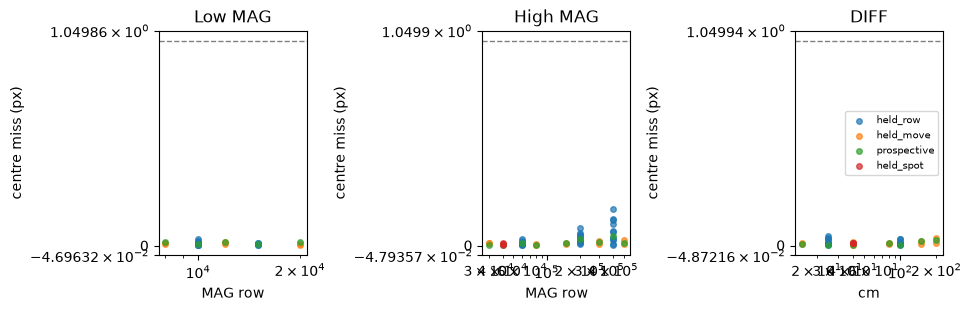

40k repeated-check range [x,y] (px): [0.006 0.024]
Random repeat noise per camera axis (px): 0.004
Scaled alignment-design rank at 1e-5 of largest singular value: 16 of 17
Observed worst / RMS held-out miss: [0.179 0.032] px
Pair-data singular values, unit-length Jacobian columns: [2.68785e+00 1.37998e+00 1.09255e+00 7.76510e-01 2.34220e-01 1.19010e-01
 7.20400e-02 1.57500e-02 4.94000e-03 4.10000e-04 0.00000e+00]
Weakest normalized parameter combination: [('Gc IL2', np.float64(0.64)), ('gap after IL1', np.float64(-0.52)), ('gap after IL2', np.float64(-0.48)), ('Gc IL3', np.float64(0.25))]
low MAG 90th percentile full-model held-out radial error (px): 0.019
low MAG lean held-out RMS versus 1 px target: 0.131
high MAG 90th percentile full-model held-out radial error (px): 0.067
high MAG lean held-out RMS versus 1 px target: 0.034
DIFF 90th percentile full-model held-out radial error (px): 0.032
DIFF lean held-out RMS versus 1 px target: 0.017


In [9]:
def distance(y):
    return np.linalg.norm(y-observed,axis=1)

print(f"{'split':12s} {'branch':10s} {'n':>4}  fixed centre   full RMS   lean RMS  full worst   (px)")
for group in ("train","held_row","held_move","prospective","held_spot","check"):
    for b,title in enumerate(("low MAG","high MAG","DIFF")):
        at = (split==group) & (branch==b)
        if at.any():
            values = [np.sqrt(np.mean(distance(y)[at]**2)) for y in (baseline,predicted,lean_prediction)]
            print(f"{group:12s} {title:10s} {at.sum():4d}", *(f"{v:10.3f}" for v in values),
                  f"{distance(predicted)[at].max():10.3f}")
test = np.isin(split,["held_row","held_move","held_spot","prospective"])
if not test.any():
    raise ValueError("No usable reserved images")
fig, ax = plt.subplots(1,3,figsize=(9.6,3),constrained_layout=True)
for b,panel in enumerate(ax):
    for group in ("held_row","held_move","prospective","held_spot"):
        here = (split==group)&(branch==b)
        if here.any():
            panel.scatter(labels[here],distance(predicted)[here],s=16,alpha=.7,label=group)
    panel.axhline(1,color="0.5",ls="--",lw=1)
    panel.set(xscale="log",yscale="symlog",xlabel="cm" if b==2 else "MAG row",
              ylabel="centre miss (px)",title=("Low MAG","High MAG","DIFF")[b])
ax[-1].legend(fontsize=7)
plt.show()

check = np.flatnonzero(split=="check")
if len(check)>=2:
    pairs = observed[check[:2*(len(check)//2)]].reshape(-1,2,2)
    repeat_sigma = np.sqrt(np.mean(np.diff(pairs,axis=1)**2)/2)
    print("40k repeated-check range [x,y] (px):",np.ptp(observed[check],axis=0).round(3))
    print("Random repeat noise per camera axis (px):",round(repeat_sigma,3))
S = np.linalg.svd(X,compute_uv=False)
print("Scaled alignment-design rank at 1e-5 of largest singular value:",sum(S>S[0]*1e-5),"of",X.shape[1])
print("Observed worst / RMS held-out miss:",np.round([max(distance(predicted)[test]),
      np.sqrt(np.mean(distance(predicted)[test]**2))],3),"px")
shape_J = np.asarray(pair_grad(strength,sense,phi_fraction,fit_pairs))[:-len(strength)]
norms = np.maximum(np.linalg.norm(shape_J,axis=0),1e-12)
_, singular, directions = np.linalg.svd(shape_J/norms,full_matrices=False)
shape_labels = ["Gc "+k for k in lens_names] + ["gap after "+k for k in lens_names[:3]] + ["Tc "+k for k in lens_names]
print("Pair-data singular values, unit-length Jacobian columns:",np.round(singular,5))
weak = directions[-1]
print("Weakest normalized parameter combination:",[(shape_labels[j],round(weak[j],2)) for j in np.argsort(-abs(weak))[:4]])
for b,title in enumerate(("low MAG","high MAG","DIFF")):
    at = test & (branch==b)
    if at.any():
        print(title, "90th percentile full-model held-out radial error (px):",round(np.quantile(distance(predicted)[at],.90),3))
        print(title,"lean held-out RMS versus 1 px target:",round(np.sqrt(np.mean(distance(lean_prediction)[at]**2)),3))

### Apply it to a console readback

Pass a proposed setting in the recorder's format and the nominal IL1, IL2, IL3 and PL1 readbacks at that selector. Look these up in the console table before a move. The public function checks the fixed controls, actual spot alignment preset, measured DAC envelope, and supported branch. Scale or rotation of a different camera requires recalibration. The two-axis inverse below requests a small detector displacement and predicts where the quantized step lands. It only calculates a command.

The repeat-check example freezes the optics and updates a camera translation from the first checks. If drift comes from source tilt, a 40k translation alone will not transfer; include separated MAG and DIFF check rows and fit their incoming-ray terms before trusting the update.

In [10]:
static_names = ["ht_v","OLc","OLf","OM","alpha","CM","condenser_hole",
                "GunA1_x","GunA1_y","GunA2_x","GunA2_y"]
def predict_setting(snapshot, nominal_projection, offset=(0.,0.)):
    if snapshot["function_mode"] not in ("MAG","DIFF"):
        raise ValueError("Expected MAG or DIFF")
    label = int(snapshot["mode_row"])
    b = 2 if snapshot["function_mode"]=="DIFF" else int(label>=30000)
    rows = train & (branch==b)
    if not labels[rows].min() <= label <= labels[rows].max() or (b==0 and label==25000):
        raise ValueError("Row outside this calibrated branch")
    for field in static_names:
        if field in frames[0] and float(snapshot[field])!=float(frames[0][field]):
            raise ValueError(f"{field} changed since calibration")
    dac = np.array([float(snapshot[k]) for k in lens_names])
    actual = np.array([float(snapshot[k]) for k in all_names])
    nominal_dac = np.asarray(nominal_projection,dtype=float)
    values = np.r_[dac,actual,nominal_dac]
    if not np.isfinite(values).all() or np.any((values<0)|(values>65535)):
        raise ValueError("Invalid DAC value")
    preset = [all_names.index("CL1"), *np.flatnonzero(tied)]
    matches = (branch==b)&(np.array([int(r["spot"]) for r in frames])==int(snapshot["spot"]))
    if not np.any(np.all(actuators[matches][:,preset]==actual[preset],axis=1)):
        raise ValueError("Unsupported spot, CL1, SpotA or stigmator preset")
    # Check actual lens displacements around the requested nominal selector.
    # Axis bounds admit simultaneous inside-range moves; the held compound tests check them.
    knots = np.unique(labels[rows])
    near = np.sort(knots[np.argsort(abs(np.log(knots/label)))[:2]])
    neighbors = rows & np.isin(labels,near)
    # The four projection lenses act in both modes. Apply a same-mode anchor bound
    # at rows where only the nominal coils were exercised (compact acquisition).
    wobbles = train & (modes==snapshot["function_mode"]) & is_wobble
    lo = np.min(lens_change[wobbles],axis=0)*1000
    hi = np.max(lens_change[wobbles],axis=0)*1000
    if b == 1 and label >= 300000:
        lo[2],hi[2] = max(lo[2],-500),min(hi[2],500)
    if np.any(dac-nominal_dac<lo-1e-8) or np.any(dac-nominal_dac>hi+1e-8):
        raise ValueError("Lens wobble outside local calibration envelope")
    for j,name in enumerate(all_names):
        support = actuators[neighbors,j]
        if name in ("CL1","CL3") or tied[j]:  # measured illumination range and joint preset above
            support = actuators[rows,j]
        if actual[j]<support.min() or actual[j]>support.max():
            raise ValueError(f"{name} outside its measured range for this branch")
    T = batched_trace(dac[None],strength,phi_fraction)
    drive, design = detector_design(T,[b],actual[None],pair_coeff,sense)
    z = (drive + design @ offset_coef)[0]
    return np.array([z.real,z.imag])+drift_at(float(snapshot.get("time_s",np.inf)))+np.asarray(offset)

i = np.flatnonzero(train & (labels==40000) & (role=="reference") & nominal)[0]
snapshot = dict(frames[i])
nominal_dac = ref_lens[branch[i],labels[i]]
at = predict_setting(snapshot, nominal_dac)
np.testing.assert_allclose(at,predicted[i],atol=1e-5)
axes = ("CLA1_x","CLA1_y")
J = np.column_stack([predict_setting(dict(snapshot, **{k:float(snapshot[k])+1}),nominal_dac)-at for k in axes])
step = np.rint(np.linalg.solve(J,[5.,-3.])).astype(int)
requested = dict(snapshot, **{k:int(float(snapshot[k]))+int(s) for k,s in zip(axes,step)})
print("Requested [5,-3] px, CLA1 increment",step,"DAC, predicted displacement",
      (predict_setting(requested,nominal_dac)-at).round(3),"px.")
if len(check)>=4:
    a,c = np.array_split(check,2)
    update = np.median(observed[a]-predicted[a],axis=0)
    before = predicted[c]-observed[c]
    print("Translation estimated from early checks:",update.round(3),"px. Later RMS before/after:",
          [round(float(np.sqrt(np.mean(np.sum((before+v)**2,axis=1)))),3) for v in (0.,update)])

Requested [5,-3] px, CLA1 increment [ 1 51] DAC, predicted displacement [ 5.017 -3.051] px.
Translation estimated from early checks: [0.003 0.   ] px. Later RMS before/after: [0.011, 0.01]


### Does the beam still fit on SightX?

The centroid can stay nearly fixed while CL3 moves a crossover through the camera. Inspect the measured one-axis RMS width as a second observable. Each spot has its own prepared CL3 readback. Interpolate width in CL1 between neighboring spots at the same *displacement from that spot’s prepared brightness*. This predicts width after beam preparation; finding the crossover from arbitrary raw CL1 and CL3 requires a wider through-focus sweep. The spot series exercises CL1, CL3 and spot alignment together. Spot 3 tests interpolation across that series. Quality-filtered sizes describe the visible cases. The excluded-frame count above also matters when planning a session.

In [11]:
width = np.array([float(r["beam_rms_px"]) for r in frames])
spots = np.array([int(r["spot"]) for r in frames])
sweep = np.array([r["setting"] == "spot CL3" for r in frames])
for b, row in [(1,40000), (2,40)]:
    fit = (branch == b) & (labels == row) & sweep & train
    test_width = (branch == b) & sweep & (split == "held_spot")
    if not (fit.sum() >= 6 and test_width.any()):
        print("Insufficient on-camera spot coverage for a width fit at", row)
        continue
    # Compare equal offsets from each spot's prepared brightness reference.
    # This is conditional on the operator/recorder finding the beam at that spot.
    dac = np.array([float(r["CL1"]) for r in frames])
    relative = np.array([float(r.get("change") or 0) if r["setting"] == "spot CL3" else 0. for r in frames])
    predicted_width = []
    for i in np.flatnonzero(test_width):
        same_step = fit & (relative == relative[i])
        order = np.argsort(dac[same_step])
        predicted_width.append(np.interp(dac[i],dac[same_step][order],width[same_step][order]))
    print(("DIFF" if b == 2 else "MAG"), row, "held spot 3 measured/predicted RMS width (px):",
          np.column_stack([width[test_width],predicted_width]).round(1).tolist())


MAG 40000 held spot 3 measured/predicted RMS width (px): [[11.8, 11.2], [26.2, 25.1], [40.8, 39.3]]
DIFF 40 held spot 3 measured/predicted RMS width (px): [[11.3, 10.9], [11.3, 10.9], [11.2, 10.8]]


## Fresh PyJEM frames

For a prospective check, freeze the predicted coordinates before asking the camera for any images. Draw three small four-lens, four-deflector-axis moves at each of five rows. Each starts at the recorded reference readbacks, with the controls approached in the same direction as in calibration. A fresh virtual microscope supplies the images. This cell runs only for a simulated recording. For real work, freeze the same kind of command-and-prediction table first, then collect the images with the operator and compare only after acquisition.

In [12]:
if frames[0].get("source") == "simulated":
    from at_the_microscope.neoarm import Neoarm, find_beam
    from datetime import datetime, timezone

    rng = np.random.default_rng(4817)
    plan = []
    for mode, label in [("MAG", 12000), ("MAG", 80000), ("MAG", 200000), ("DIFF", 25), ("DIFF", 80)]:
        available = {int(r["mode_row"]) for r in frames if r["function_mode"] == mode and r["setting"] == "row"
                     and r["role"] == "reference" and (mode == "DIFF" or (int(r["mode_row"])<30000)==(label<30000))}
        label = min(available,key=lambda candidate: (abs(np.log(candidate/label)),candidate))
        home = next(r for r in frames if r["function_mode"] == mode and int(r["mode_row"]) == label
                    and r["role"] == "reference" and r["setting"] == "row")
        nominal_dac = np.array([int(home[k]) for k in lens_names])
        strong = "CLA2" if mode == "DIFF" else "CLA1"
        scale = next(int(r["kick"]) for r in frames if r["function_mode"] == mode and int(r["mode_row"]) == label
                     and r["setting"] == "row" and r.get("deflector") == strong)
        for _ in range(3):
            cmd = dict(home)
            for k in lens_names:
                cmd[k] = int(home[k]) + int(rng.integers(-190, 191))
            for coil in ("CLA1", "CLA2"):
                span = min(scale//4, 240) if coil == strong else 110
                for axis in ("x", "y"):
                    k = coil + "_" + axis
                    cmd[k] = int(home[k]) + int(rng.integers(-span, span+1))
            prediction = predict_setting(cmd, nominal_dac)
            plan.append(dict(mode=mode, label=label, spot=int(cmd["spot"]), CL3=int(cmd["CL3"]),
                             **{k:int(cmd[k]) for k in (*lens_names, "CLA1_x", "CLA1_y", "CLA2_x", "CLA2_y")},
                             x_px=float(prediction[0]), y_px=float(prediction[1])))

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    ledger = session / f"prospective_{stamp}.json"
    ledger.write_text(json.dumps(plan, indent=2))
    print(f"{len(plan)} predictions frozen in {ledger.name}")

15 predictions frozen in prospective_20261118T000316552489Z.json


Simulated NEOARM
dark level: 3.0


Simulated NEOARM
dark level: 3.0


Simulated NEOARM
dark level: 3.0


Simulated NEOARM
dark level: 3.0


Simulated NEOARM
dark level: 3.0


MAG: 9/9 usable, RMS 0.01 px, worst 0.02 px
DIFF: 6/6 usable, RMS 0.01 px, worst 0.01 px


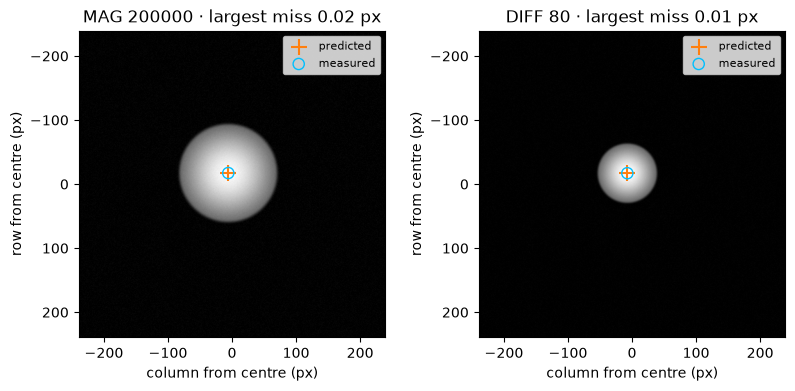

In [13]:
if frames[0].get("source") == "simulated":
    from itertools import groupby
    reports = []
    examples = {}
    for (mode, label), moves in groupby(plan, key=lambda move: (move["mode"], move["label"])):
        scope = Neoarm("fresh", simulated=True, magnification=label if mode == "MAG" else 40000,
                       camera_length_m=label/100 if mode == "DIFF" else 0.4)
        scope.eos.SelectFunctionMode(4 if mode == "DIFF" else 0)
        assert scope.eos.GetMagValue()[0] == label
        scope.measure_dark_level()
        for cmd in moves:
            scope.eos.SelectSpotSize(cmd["spot"])
            scope.take_over("CL3", *lens_names)
            target = {key:cmd[key] for key in ("CL3", *lens_names)}
            scope.set_lenses(**{k:max(0,v-2000) for k,v in target.items()})
            scope.set_lenses(**target)
            for coil in ("CLA1", "CLA2"):
                scope.set_deflector(coil, cmd[coil+"_x"], cmd[coil+"_y"])
            actual = scope.read_state()
            assert all(actual[k] == cmd[k] for k in (*target, "CLA1_x", "CLA1_y", "CLA2_x", "CLA2_y"))
            image = scope.take_frame()
            beam = find_beam(frame=image, background=scope.dark_level)
            miss = abs(beam.centre-complex(cmd["x_px"],cmd["y_px"])) if beam.usable and not beam.saturated else None
            if miss is not None and (mode not in examples or miss > examples[mode][0]):
                examples[mode] = (miss, image, cmd, beam)
            reports.append(dict(**cmd, measured_x=beam.centre.real, measured_y=beam.centre.imag, miss_px=miss))
    ledger.with_suffix(".scored.json").write_text(json.dumps(reports, indent=2))
    for mode in ("MAG", "DIFF"):
        subset = [r for r in reports if r["mode"] == mode]
        errors = [r["miss_px"] for r in subset if r["miss_px"] is not None]
        if errors:
            print(f"{mode}: {len(errors)}/{len(subset)} usable, RMS {np.sqrt(np.mean(np.square(errors))):.2f} px, "
                  f"worst {max(errors):.2f} px")
        else:
            print(f"{mode}: none of the {len(subset)} prospective frames were usable")
    if examples:
        fig, axes = plt.subplots(1, len(examples), figsize=(4*len(examples), 3.8), squeeze=False, layout="constrained")
        for ax, (mode, (miss, image, cmd, beam)) in zip(axes.flat, examples.items()):
            ny, nx = image.shape
            ax.imshow(np.sqrt(np.maximum(image.astype(float)-np.median(image), 0)), cmap="gray",
                      extent=(-nx/2, nx/2, ny/2, -ny/2))
            ax.scatter(cmd["x_px"], cmd["y_px"], marker="+", color="tab:orange", s=130, label="predicted")
            ax.scatter(beam.centre.real, beam.centre.imag, facecolors="none", edgecolors="deepskyblue", s=65, label="measured")
            ax.set(title=f'{mode} {cmd["label"]} · largest miss {miss:.2f} px', xlabel="column from centre (px)", ylabel="row from centre (px)")
            ax.legend(loc="upper right", fontsize=8)
        plt.show()

### What the two rehearsals established

The saved plots and comparison table above use the broad simulator recording `2026-11-17_234820`. Its **599 usable training images** gave a radial centre error of **0.032 px RMS** on 132 reserved images. Removing everything except the compact recipe from its training set retained subpixel accuracy.

We then ran the compact recording script on a fresh simulator session, `2026-11-18_000041`, and fitted the notebook independently. It used **160 training images**, saved 288 usable images including checks and validation, and took 460 exposures including setup, dark and centring frames. Across its reserved rows, movements and spot, the centre errors were **0.126 px RMS in low MAG, 0.032 px in high MAG and 0.017 px in DIFF**. The worst miss was 0.304 px. Fifteen further commands were predicted, saved, then imaged. All 15 beams were measurable. Fresh MAG misses were 0.07 px RMS (worst 0.17), and fresh DIFF misses were 0.01 px RMS (worst 0.02).

The simulator supports the two-anchor lens-wobble design under these controls and approaches. The real instrument still needs its branch-alignment kicks, spot tests, calibrations and independent validation. Differences between stable 40k returns, or systematic errors on an entire held row, are grounds to revisit the session alignment or add a wobble there. Single-plane pixel accuracy leaves lens-position trade-offs that require the rulers and independent camera plane in notebook one.

The default loader takes the latest complete pilot. Set `NEOARM_PILOT` to the desired dated folder under `at_the_microscope/output/predictor/` to reproduce either rehearsal.